# Wallpaper Visualization Pipeline

This notebook implements a depth-based wallpaper texture overlay system that:
1. Computes surface normals from depth maps
2. Clusters wall pixels into planar regions
3. Establishes UV coordinate systems per plane
4. Applies tiled wallpaper textures with lighting preservation

Each step includes visualizations for debugging and parameter tuning.

## 1. Setup & Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D
import cv2
from scipy.ndimage import gaussian_filter, sobel
from sklearn.cluster import DBSCAN
import ipywidgets as widgets
from IPython.display import display, HTML
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set up matplotlib for better inline display
%matplotlib inline
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['figure.dpi'] = 100

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [2]:
# Helper function for displaying images side-by-side
def show_images(images, titles, figsize=(15, 5), cmap=None):
    """
    Display multiple images side by side.
    
    Args:
        images: List of numpy arrays
        titles: List of titles for each image
        figsize: Figure size tuple
        cmap: Colormap (can be single value or list)
    """
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    
    for i, (img, title) in enumerate(zip(images, titles)):
        if isinstance(cmap, list):
            c = cmap[i]
        else:
            c = cmap
        
        if len(img.shape) == 2:
            axes[i].imshow(img, cmap=c if c else 'viridis')
        else:
            axes[i].imshow(img)
        axes[i].set_title(title)
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

def normalize_for_display(img):
    """Normalize image to 0-255 range for display."""
    img = img.copy()
    img = img - img.min()
    img = img / (img.max() + 1e-8)
    return (img * 255).astype(np.uint8)

print("✓ Helper functions defined")

✓ Helper functions defined


## 2. Load Input Data

Specify the paths to your test data files below.

In [10]:
# === CONFIGURE YOUR DATA PATHS HERE ===
DATA_DIR = Path("/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/")

# Example paths - UPDATE THESE to match your actual file names
rgb_image_path = DATA_DIR / "bed_back_bedroom.jpg"
depth_map_path = DATA_DIR / "bed_back_depth.npy"
wall_mask_path = DATA_DIR / "bed_back_bedroom_wall_confidence.npy"
wallpaper_path = Path("/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/images/graphite-clay-repeated-patterns-coordonne.jpg")

print(f"Data directory: {DATA_DIR}")
print(f"\nExpected files:")
print(f"  RGB image: {rgb_image_path.name}")
print(f"  Depth map: {depth_map_path.name}")
print(f"  Wall mask: {wall_mask_path.name}")
print(f"  Wallpaper: {wallpaper_path.name}")

Data directory: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom

Expected files:
  RGB image: bed_back_bedroom.jpg
  Depth map: bed_back_depth.npy
  Wall mask: bed_back_bedroom_wall_confidence.npy
  Wallpaper: graphite-clay-repeated-patterns-coordonne.jpg


In [11]:
# Load RGB image
try:
    rgb_image = cv2.imread(str(rgb_image_path))
    rgb_image = cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB)
    print(f"✓ RGB image loaded: {rgb_image.shape}")
except Exception as e:
    print(f"✗ Error loading RGB image: {e}")
    rgb_image = None

# Load depth map
try:
    depth_map = np.load(str(depth_map_path))
    print(f"✓ Depth map loaded: {depth_map.shape}")
    print(f"  Depth range: {depth_map.min():.3f} to {depth_map.max():.3f}")
except Exception as e:
    print(f"✗ Error loading depth map: {e}")
    depth_map = None

# Load wall mask
try:
    wall_mask = np.load(str(wall_mask_path))
    if wall_mask.dtype != bool:
        wall_mask = wall_mask > 0.5  # Convert to boolean
    print(f"✓ Wall mask loaded: {wall_mask.shape}")
    print(f"  Wall pixels: {wall_mask.sum()} ({100*wall_mask.sum()/wall_mask.size:.1f}%)")
except Exception as e:
    print(f"✗ Error loading wall mask: {e}")
    wall_mask = None

# Load wallpaper texture
try:
    wallpaper = cv2.imread(str(wallpaper_path))
    wallpaper = cv2.cvtColor(wallpaper, cv2.COLOR_BGR2RGB)
    print(f"✓ Wallpaper loaded: {wallpaper.shape}")
except Exception as e:
    print(f"✗ Error loading wallpaper: {e}")
    wallpaper = None

✓ RGB image loaded: (700, 1200, 3)
✓ Depth map loaded: (700, 1200)
  Depth range: 0.971 to 17.841
✓ Wall mask loaded: (700, 1200)
  Wall pixels: 234667 (27.9%)
✓ Wallpaper loaded: (2500, 2134, 3)


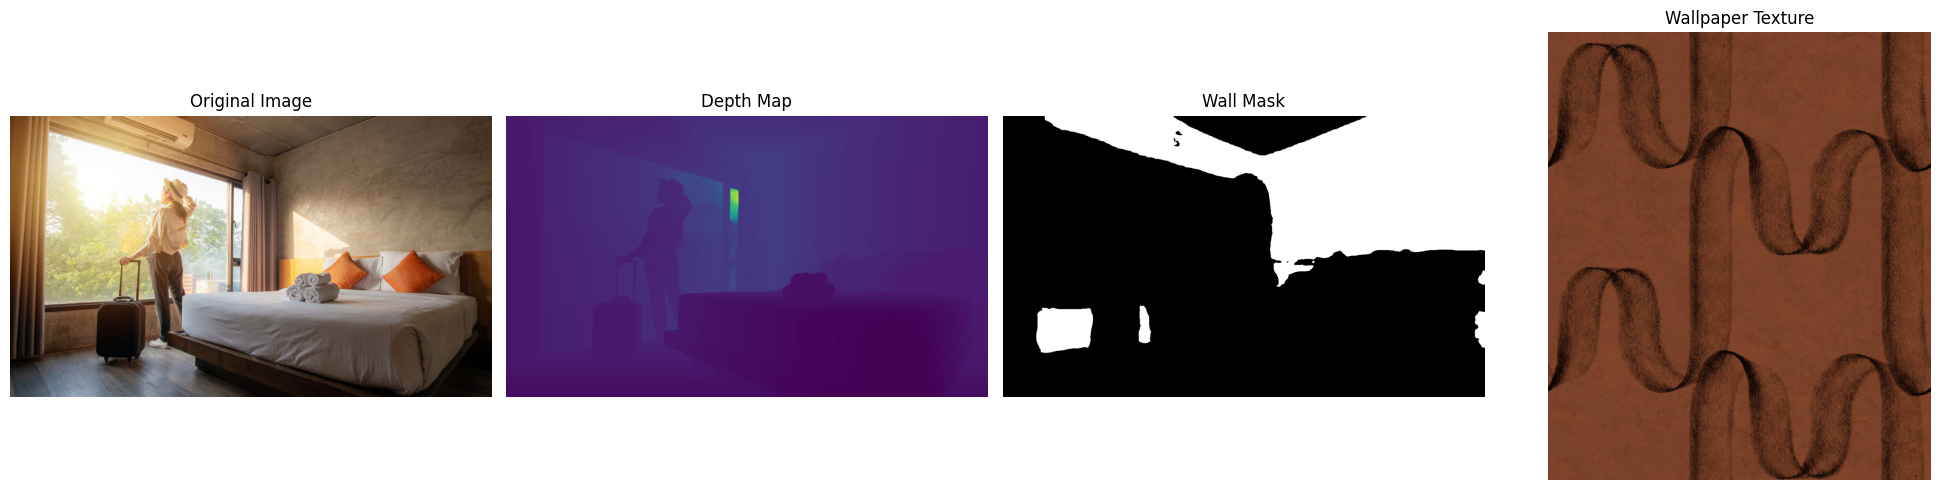

In [12]:
# Display all inputs
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    show_images(
        [rgb_image, normalize_for_display(depth_map), wall_mask.astype(np.uint8)*255, wallpaper],
        ['Original Image', 'Depth Map', 'Wall Mask', 'Wallpaper Texture'],
        figsize=(20, 5),
        cmap=[None, 'viridis', 'gray', None]
    )
else:
    print("⚠ Some inputs failed to load. Please check file paths above.")

## 3. Interactive Parameters

Adjust these parameters to tune the pipeline behavior.

In [13]:
# Global parameters - adjust these as needed
params = {
    'pattern_width_m': 0.53,      # Wallpaper pattern width in meters
    'pattern_height_m': 1.0,      # Wallpaper pattern height in meters
    'gaussian_sigma': 2.0,        # Depth smoothing (higher = smoother)
    'dbscan_eps': 0.1,            # Plane clustering tolerance (smaller = stricter)
    'dbscan_min_samples': 100,    # Minimum samples for DBSCAN core points
    'min_cluster_size': 1000,     # Minimum pixels for valid plane
    'fx_multiplier': 0.8,         # Camera focal length multiplier
}

print("Current parameters:")
for key, value in params.items():
    print(f"  {key}: {value}")

Current parameters:
  pattern_width_m: 0.53
  pattern_height_m: 1.0
  gaussian_sigma: 2.0
  dbscan_eps: 0.1
  dbscan_min_samples: 100
  min_cluster_size: 1000
  fx_multiplier: 0.8


## 4. Step 1: Compute Surface Normals

Extract per-pixel normal vectors from depth gradients.

In [14]:
def compute_normals(depth, mask, sigma=2.0):
    """
    Compute surface normals from depth map.
    
    Args:
        depth: (H, W) depth map
        mask: (H, W) boolean mask for valid regions
        sigma: Gaussian smoothing parameter
    
    Returns:
        normals: (H, W, 3) normalized normal vectors
    """
    # Smooth depth to reduce noise
    depth_smooth = gaussian_filter(depth, sigma=sigma)
    
    # Compute gradients
    dz_dx = sobel(depth_smooth, axis=1, mode='constant')  # horizontal gradient
    dz_dy = sobel(depth_smooth, axis=0, mode='constant')  # vertical gradient
    
    # Normal = (-dz/dx, -dz/dy, 1), then normalize
    normals = np.stack([-dz_dx, -dz_dy, np.ones_like(depth)], axis=-1)
    
    # Normalize to unit vectors
    norm = np.linalg.norm(normals, axis=-1, keepdims=True) + 1e-8
    normals = normals / norm
    
    # Mask to valid region only
    normals[~mask] = 0
    
    return normals, depth_smooth, dz_dx, dz_dy

print("✓ compute_normals() function defined")

✓ compute_normals() function defined


In [15]:
# Compute normals
if depth_map is not None and wall_mask is not None:
    normals, depth_smooth, dz_dx, dz_dy = compute_normals(
        depth_map, 
        wall_mask, 
        sigma=params['gaussian_sigma']
    )
    
    print(f"✓ Normals computed: {normals.shape}")
    print(f"  Normal range X: [{normals[..., 0].min():.3f}, {normals[..., 0].max():.3f}]")
    print(f"  Normal range Y: [{normals[..., 1].min():.3f}, {normals[..., 1].max():.3f}]")
    print(f"  Normal range Z: [{normals[..., 2].min():.3f}, {normals[..., 2].max():.3f}]")
else:
    print("⚠ Cannot compute normals - depth map or mask not loaded")

✓ Normals computed: (700, 1200, 3)
  Normal range X: [-0.665, 0.994]
  Normal range Y: [-0.997, 0.844]
  Normal range Z: [0.000, 1.000]


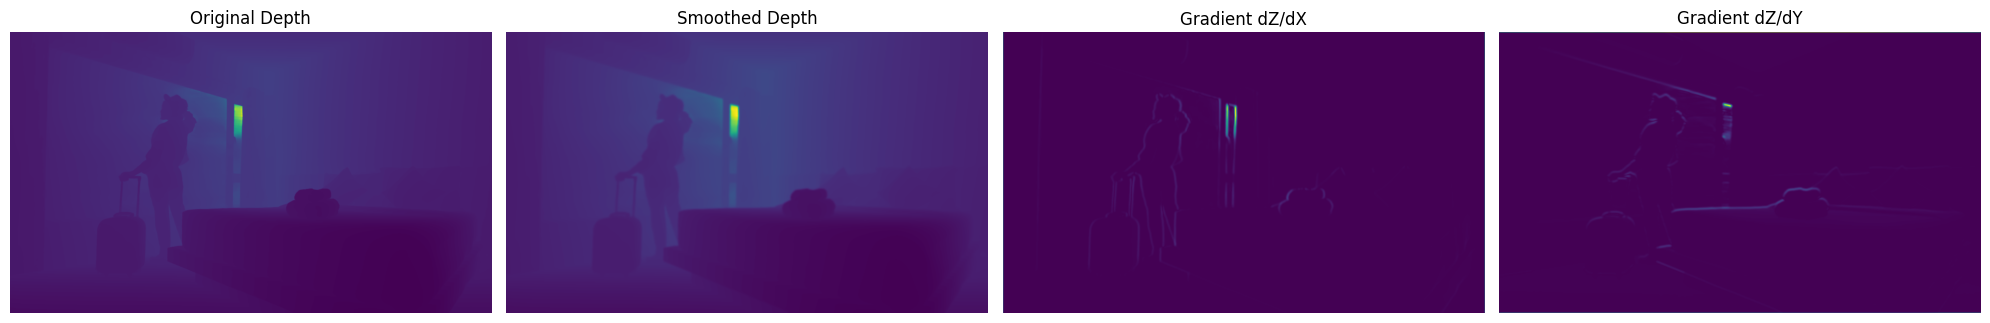

In [16]:
# Visualize depth processing
if depth_map is not None and wall_mask is not None:
    show_images(
        [depth_map, depth_smooth, normalize_for_display(np.abs(dz_dx)), normalize_for_display(np.abs(dz_dy))],
        ['Original Depth', 'Smoothed Depth', 'Gradient dZ/dX', 'Gradient dZ/dY'],
        figsize=(20, 5),
        cmap='viridis'
    )

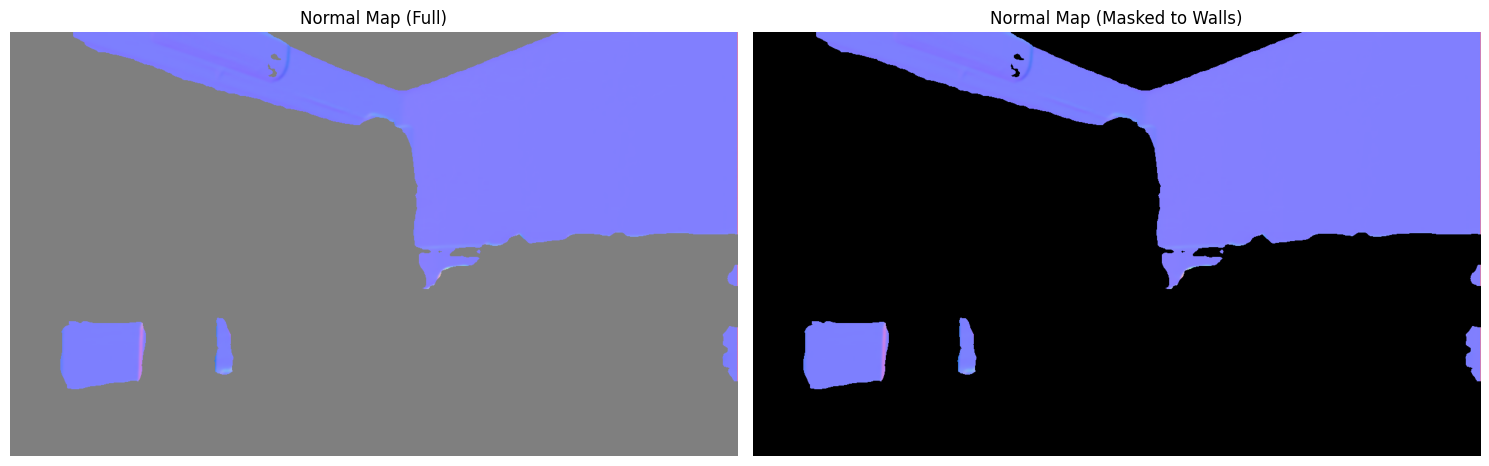

In [17]:
# Visualize normals as RGB (X→R, Y→G, Z→B)
if depth_map is not None and wall_mask is not None:
    # Convert normals from [-1, 1] to [0, 255] for visualization
    normals_vis = ((normals + 1) * 127.5).astype(np.uint8)
    normals_masked = normals_vis.copy()
    normals_masked[~wall_mask] = 0
    
    show_images(
        [normals_vis, normals_masked],
        ['Normal Map (Full)', 'Normal Map (Masked to Walls)'],
        figsize=(15, 7)
    )

## 5. Step 2: Cluster Wall Pixels into Planes

Group wall pixels by similar normal directions to identify distinct planar surfaces.

In [18]:
def cluster_wall_planes(normals, mask, eps=0.1, min_samples=100, min_cluster_size=1000):
    """
    Cluster wall pixels by normal direction.
    
    Args:
        normals: (H, W, 3) normal vectors
        mask: (H, W) boolean mask
        eps: DBSCAN epsilon (normal similarity threshold)
        min_samples: DBSCAN minimum samples
        min_cluster_size: Minimum pixels for valid cluster
    
    Returns:
        labels: (H, W) array with plane labels (-1 = no plane)
    """
    # Extract normals for wall pixels only
    wall_coords = np.argwhere(mask)  # (N, 2) - row, col positions
    wall_normals = normals[mask]     # (N, 3)
    
    print(f"  Clustering {len(wall_normals)} wall pixels...")
    
    # Cluster by normal direction
    clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(wall_normals)
    
    # Build label map
    labels = np.full(mask.shape, -1, dtype=np.int32)
    labels[mask] = clustering.labels_
    
    # Filter tiny clusters
    unique_labels = np.unique(labels)
    for label in unique_labels:
        if label == -1:
            continue
        cluster_size = (labels == label).sum()
        if cluster_size < min_cluster_size:
            labels[labels == label] = -1
    
    return labels

print("✓ cluster_wall_planes() function defined")

✓ cluster_wall_planes() function defined


In [19]:
# Cluster planes
if depth_map is not None and wall_mask is not None:
    labels = cluster_wall_planes(
        normals,
        wall_mask,
        eps=params['dbscan_eps'],
        min_samples=params['dbscan_min_samples'],
        min_cluster_size=params['min_cluster_size']
    )
    
    unique_labels = [l for l in np.unique(labels) if l >= 0]
    print(f"\n✓ Found {len(unique_labels)} plane clusters")
    
    # Print cluster statistics
    for label in unique_labels:
        cluster_size = (labels == label).sum()
        percentage = 100 * cluster_size / wall_mask.sum()
        print(f"  Plane {label}: {cluster_size} pixels ({percentage:.1f}% of walls)")
else:
    print("⚠ Cannot cluster planes - normals not computed")

  Clustering 234667 wall pixels...


: 

In [ ]:
# Visualize plane clusters
if depth_map is not None and wall_mask is not None:
    # Create colored label map
    labels_colored = np.zeros((*labels.shape, 3), dtype=np.uint8)
    colors = plt.cm.tab10(np.linspace(0, 1, 10))[:, :3] * 255
    
    for i, label in enumerate(unique_labels):
        color = colors[i % len(colors)]
        labels_colored[labels == label] = color
    
    # Overlay on original image
    overlay = rgb_image.copy().astype(np.float32)
    alpha = 0.6
    mask_3d = (labels >= 0)[..., None]
    overlay = overlay * (1 - alpha * mask_3d) + labels_colored * alpha * mask_3d
    overlay = overlay.astype(np.uint8)
    
    show_images(
        [labels_colored, overlay],
        [f'Plane Clusters ({len(unique_labels)} planes)', 'Clusters Overlaid on Image'],
        figsize=(15, 7)
    )

In [ ]:
# Cluster size distribution
if depth_map is not None and wall_mask is not None:
    cluster_sizes = []
    cluster_labels = []
    for label in unique_labels:
        cluster_sizes.append((labels == label).sum())
        cluster_labels.append(f"Plane {label}")
    
    plt.figure(figsize=(10, 5))
    plt.bar(cluster_labels, cluster_sizes, color=colors[:len(unique_labels)])
    plt.xlabel('Plane Label')
    plt.ylabel('Number of Pixels')
    plt.title('Cluster Size Distribution')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 6. Step 3: Fit Plane Normals

Compute one representative normal vector per plane cluster.

In [ ]:
def fit_plane_normals(normals, labels):
    """
    Compute one representative normal per plane cluster.
    
    Args:
        normals: (H, W, 3) normal vectors
        labels: (H, W) plane labels
    
    Returns:
        plane_normals: dict {label: normal_vector}
    """
    plane_normals = {}
    
    for label in np.unique(labels):
        if label == -1:
            continue
        
        cluster_normals = normals[labels == label]
        
        # Average normals and re-normalize
        avg_normal = cluster_normals.mean(axis=0)
        avg_normal = avg_normal / (np.linalg.norm(avg_normal) + 1e-8)
        
        plane_normals[label] = avg_normal
    
    return plane_normals

print("✓ fit_plane_normals() function defined")

In [ ]:
# Fit plane normals
if depth_map is not None and wall_mask is not None:
    plane_normals = fit_plane_normals(normals, labels)
    
    print(f"\n✓ Fitted {len(plane_normals)} plane normals:")
    print("\nPlane | Normal Vector (X, Y, Z)")
    print("-" * 45)
    for label, normal in plane_normals.items():
        print(f"  {label:2d}  | ({normal[0]:7.4f}, {normal[1]:7.4f}, {normal[2]:7.4f})")
else:
    print("⚠ Cannot fit plane normals - labels not computed")

In [ ]:
# Visualize plane normals in 3D
if depth_map is not None and wall_mask is not None and len(plane_normals) > 0:
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # Plot axes
    ax.quiver(0, 0, 0, 1, 0, 0, color='r', arrow_length_ratio=0.1, linewidth=2, label='X')
    ax.quiver(0, 0, 0, 0, 1, 0, color='g', arrow_length_ratio=0.1, linewidth=2, label='Y')
    ax.quiver(0, 0, 0, 0, 0, 1, color='b', arrow_length_ratio=0.1, linewidth=2, label='Z')
    
    # Plot plane normals
    for i, (label, normal) in enumerate(plane_normals.items()):
        color = colors[i % len(colors)]
        ax.quiver(0, 0, 0, normal[0], normal[1], normal[2], 
                 color=color, arrow_length_ratio=0.1, linewidth=3, 
                 label=f'Plane {label}')
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_xlim([-1, 1])
    ax.set_ylim([-1, 1])
    ax.set_zlim([-1, 1])
    ax.legend()
    ax.set_title('Plane Normal Vectors')
    plt.show()

In [ ]:
# Compute angles between planes (if multiple exist)
if depth_map is not None and wall_mask is not None and len(plane_normals) > 1:
    print("\nAngles between planes (degrees):")
    print("-" * 40)
    labels_list = list(plane_normals.keys())
    for i in range(len(labels_list)):
        for j in range(i+1, len(labels_list)):
            n1 = plane_normals[labels_list[i]]
            n2 = plane_normals[labels_list[j]]
            dot_product = np.dot(n1, n2)
            angle = np.arccos(np.clip(dot_product, -1, 1)) * 180 / np.pi
            print(f"  Plane {labels_list[i]} ↔ Plane {labels_list[j]}: {angle:.1f}°")

## 7. Step 4: Build UV Coordinate System

For each plane, define orthonormal basis vectors (u=horizontal, v=vertical).

In [ ]:
def build_plane_basis(normal):
    """
    Given a plane normal, return orthonormal (u_axis, v_axis) on the plane.
    
    Args:
        normal: (3,) unit normal vector
    
    Returns:
        u_axis: (3,) horizontal axis on plane
        v_axis: (3,) vertical axis on plane (aligned with gravity)
    """
    # Assume gravity is -Y in camera space
    up = np.array([0, -1, 0], dtype=np.float64)
    
    # v_axis: project "up" onto plane, normalize
    v_axis = up - np.dot(up, normal) * normal
    v_axis = v_axis / (np.linalg.norm(v_axis) + 1e-8)
    
    # u_axis: perpendicular to both normal and v
    u_axis = np.cross(normal, v_axis)
    u_axis = u_axis / (np.linalg.norm(u_axis) + 1e-8)
    
    return u_axis, v_axis

print("✓ build_plane_basis() function defined")

In [ ]:
# Build basis vectors for each plane
if depth_map is not None and wall_mask is not None:
    plane_bases = {}
    
    print("\nPlane basis vectors:")
    print("-" * 80)
    print("Plane | U-axis (X, Y, Z)           | V-axis (X, Y, Z)")
    print("-" * 80)
    
    for label, normal in plane_normals.items():
        u_axis, v_axis = build_plane_basis(normal)
        plane_bases[label] = (u_axis, v_axis)
        
        print(f"  {label:2d}  | ({u_axis[0]:7.4f}, {u_axis[1]:7.4f}, {u_axis[2]:7.4f}) | "
              f"({v_axis[0]:7.4f}, {v_axis[1]:7.4f}, {v_axis[2]:7.4f})")
else:
    print("⚠ Cannot build plane bases - plane normals not computed")

In [ ]:
# Verify orthonormality
if depth_map is not None and wall_mask is not None:
    print("\nOrthonormality verification (should all be ≈0):")
    print("-" * 60)
    
    for label in plane_normals.keys():
        normal = plane_normals[label]
        u_axis, v_axis = plane_bases[label]
        
        # Check orthogonality
        dot_nu = np.dot(normal, u_axis)
        dot_nv = np.dot(normal, v_axis)
        dot_uv = np.dot(u_axis, v_axis)
        
        print(f"  Plane {label}: N·U={dot_nu:.6f}, N·V={dot_nv:.6f}, U·V={dot_uv:.6f}")

## 8. Step 5: Unproject Pixels to 3D

Convert depth map to 3D point cloud using camera intrinsics.

In [ ]:
def unproject_to_3d(depth, fx, fy, cx, cy):
    """
    Unproject depth map to 3D point cloud.
    
    Args:
        depth: (H, W) depth map
        fx, fy: Focal lengths in pixels
        cx, cy: Principal point coordinates
    
    Returns:
        points_3d: (H, W, 3) XYZ coordinates
    """
    H, W = depth.shape
    u, v = np.meshgrid(np.arange(W), np.arange(H))
    
    Z = depth
    X = (u - cx) * Z / fx
    Y = (v - cy) * Z / fy
    
    points_3d = np.stack([X, Y, Z], axis=-1)
    
    return points_3d

print("✓ unproject_to_3d() function defined")

In [ ]:
# Estimate camera intrinsics and unproject
if depth_map is not None:
    H, W = depth_map.shape
    
    # Estimate intrinsics
    fx = fy = W * params['fx_multiplier']
    cx, cy = W / 2, H / 2
    
    print(f"\nEstimated camera intrinsics:")
    print(f"  Image size: {W} × {H}")
    print(f"  Focal length: fx={fx:.1f}, fy={fy:.1f}")
    print(f"  Principal point: cx={cx:.1f}, cy={cy:.1f}")
    
    # Unproject to 3D
    points_3d = unproject_to_3d(depth_map, fx, fy, cx, cy)
    
    print(f"\n✓ Point cloud generated: {points_3d.shape}")
    print(f"  X range: [{points_3d[..., 0].min():.3f}, {points_3d[..., 0].max():.3f}]")
    print(f"  Y range: [{points_3d[..., 1].min():.3f}, {points_3d[..., 1].max():.3f}]")
    print(f"  Z range: [{points_3d[..., 2].min():.3f}, {points_3d[..., 2].max():.3f}]")
else:
    print("⚠ Cannot unproject - depth map not loaded")

In [ ]:
# Visualize 3D point cloud
if depth_map is not None and wall_mask is not None:
    # Sample points for visualization (full cloud is too dense)
    step = 10
    wall_points = points_3d[wall_mask]
    sampled_indices = np.random.choice(len(wall_points), 
                                      size=min(5000, len(wall_points)), 
                                      replace=False)
    sampled_points = wall_points[sampled_indices]
    
    # Get colors for sampled points
    wall_labels = labels[wall_mask]
    sampled_labels = wall_labels[sampled_indices]
    sampled_colors = np.zeros((len(sampled_points), 3))
    for i, label in enumerate(unique_labels):
        mask_label = sampled_labels == label
        sampled_colors[mask_label] = colors[i % len(colors)][:3]
    
    # 3D scatter plot
    fig = plt.figure(figsize=(15, 5))
    
    # Colored by cluster
    ax1 = fig.add_subplot(131, projection='3d')
    ax1.scatter(sampled_points[:, 0], sampled_points[:, 1], sampled_points[:, 2],
               c=sampled_colors, s=1, alpha=0.5)
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    ax1.set_title('Point Cloud (Colored by Plane)')
    
    # XY projection
    ax2 = fig.add_subplot(132)
    ax2.scatter(sampled_points[:, 0], sampled_points[:, 1],
               c=sampled_colors, s=1, alpha=0.5)
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_title('XY Projection (Top View)')
    ax2.set_aspect('equal')
    
    # XZ projection
    ax3 = fig.add_subplot(133)
    ax3.scatter(sampled_points[:, 0], sampled_points[:, 2],
               c=sampled_colors, s=1, alpha=0.5)
    ax3.set_xlabel('X')
    ax3.set_ylabel('Z (Depth)')
    ax3.set_title('XZ Projection (Side View)')
    ax3.set_aspect('equal')
    
    plt.tight_layout()
    plt.show()

## 9. Step 6: Compute UV Coordinates

Project 3D points onto each plane's basis vectors to get texture coordinates.

In [ ]:
def compute_uv_coordinates(points_3d, labels, plane_normals):
    """
    Compute (u, v) texture coordinates for each wall pixel.
    
    Args:
        points_3d: (H, W, 3) 3D point cloud
        labels: (H, W) plane labels
        plane_normals: dict {label: normal_vector}
    
    Returns:
        uv_map: (H, W, 2) UV coordinates in meters
    """
    H, W = labels.shape
    uv_map = np.zeros((H, W, 2), dtype=np.float64)
    
    for label, normal in plane_normals.items():
        plane_mask = (labels == label)
        plane_points = points_3d[plane_mask]  # (N, 3)
        
        if len(plane_points) == 0:
            continue
        
        # Get plane basis
        u_axis, v_axis = build_plane_basis(normal)
        
        # Pick origin: mean of plane points
        origin = plane_points.mean(axis=0)
        
        # Project onto plane axes
        relative = plane_points - origin
        u_coords = relative @ u_axis
        v_coords = relative @ v_axis
        
        uv_map[plane_mask, 0] = u_coords
        uv_map[plane_mask, 1] = v_coords
    
    return uv_map

print("✓ compute_uv_coordinates() function defined")

In [ ]:
# Compute UV coordinates
if depth_map is not None and wall_mask is not None:
    uv_map = compute_uv_coordinates(points_3d, labels, plane_normals)
    
    print(f"\n✓ UV coordinates computed: {uv_map.shape}")
    
    # Print UV range for each plane
    print("\nUV coordinate ranges per plane (meters):")
    print("-" * 60)
    print("Plane | U range             | V range")
    print("-" * 60)
    
    for label in plane_normals.keys():
        plane_mask = (labels == label)
        u_vals = uv_map[plane_mask, 0]
        v_vals = uv_map[plane_mask, 1]
        
        u_range = u_vals.max() - u_vals.min()
        v_range = v_vals.max() - v_vals.min()
        
        print(f"  {label:2d}  | [{u_vals.min():6.2f}, {u_vals.max():6.2f}] | "
              f"[{v_vals.min():6.2f}, {v_vals.max():6.2f}]")
        print(f"       | Range: {u_range:6.2f}m      | Range: {v_range:6.2f}m")
else:
    print("⚠ Cannot compute UV coordinates - required data not available")

In [ ]:
# Visualize UV coordinates
if depth_map is not None and wall_mask is not None:
    # Normalize UV for display
    u_display = normalize_for_display(uv_map[..., 0])
    v_display = normalize_for_display(uv_map[..., 1])
    
    # Mask out non-wall regions
    wall_mask_3d = (labels >= 0)
    u_display[~wall_mask_3d] = 0
    v_display[~wall_mask_3d] = 0
    
    show_images(
        [u_display, v_display],
        ['U Coordinates (Horizontal)', 'V Coordinates (Vertical)'],
        figsize=(15, 7),
        cmap='coolwarm'
    )

## 10. Step 7: Sample Wallpaper Texture

Map UV coordinates (in meters) to wallpaper pixels with tiling.

In [ ]:
def sample_wallpaper(uv_map, labels, wallpaper, pattern_width_m, pattern_height_m):
    """
    Sample wallpaper color for each wall pixel.
    
    Args:
        uv_map: (H, W, 2) UV coordinates in meters
        labels: (H, W) plane labels
        wallpaper: (Ph, Pw, 3) pattern image
        pattern_width_m: Physical width of pattern in meters
        pattern_height_m: Physical height of pattern in meters
    
    Returns:
        sampled: (H, W, 3) sampled wallpaper colors
    """
    H, W = labels.shape
    Ph, Pw = wallpaper.shape[:2]
    
    result = np.zeros((H, W, 3), dtype=np.uint8)
    wall_mask = labels >= 0
    
    # Convert meters → pattern pixels, with tiling
    u_meters = uv_map[wall_mask, 0]
    v_meters = uv_map[wall_mask, 1]
    
    # Normalize to [0, 1] within pattern, then tile
    u_norm = (u_meters / pattern_width_m) % 1.0
    v_norm = (v_meters / pattern_height_m) % 1.0
    
    # Convert to pixel indices
    px = (u_norm * (Pw - 1)).astype(np.int32)
    py = (v_norm * (Ph - 1)).astype(np.int32)
    
    # Clamp to valid range (safety)
    px = np.clip(px, 0, Pw - 1)
    py = np.clip(py, 0, Ph - 1)
    
    # Sample
    result[wall_mask] = wallpaper[py, px]
    
    return result

print("✓ sample_wallpaper() function defined")

In [ ]:
# Sample wallpaper texture
if all(x is not None for x in [depth_map, wall_mask, wallpaper]):
    wallpaper_sampled = sample_wallpaper(
        uv_map,
        labels,
        wallpaper,
        params['pattern_width_m'],
        params['pattern_height_m']
    )
    
    print(f"\n✓ Wallpaper sampled: {wallpaper_sampled.shape}")
    print(f"\nPattern dimensions: {params['pattern_width_m']}m × {params['pattern_height_m']}m")
    print(f"Wallpaper resolution: {wallpaper.shape[1]} × {wallpaper.shape[0]} pixels")
    
    # Calculate physical pixel density
    pixels_per_meter_u = wallpaper.shape[1] / params['pattern_width_m']
    pixels_per_meter_v = wallpaper.shape[0] / params['pattern_height_m']
    print(f"Physical resolution: {pixels_per_meter_u:.1f} × {pixels_per_meter_v:.1f} pixels/meter")
else:
    print("⚠ Cannot sample wallpaper - required data not available")

In [ ]:
# Visualize sampled wallpaper
if all(x is not None for x in [depth_map, wall_mask, wallpaper]):
    show_images(
        [rgb_image, wallpaper_sampled, wallpaper],
        ['Original Image', 'Sampled Wallpaper (No Lighting)', 'Wallpaper Pattern'],
        figsize=(20, 7)
    )

## 11. Step 8: Composite with Lighting Preservation

Transfer original lighting onto the wallpaper texture.

In [ ]:
def composite_with_lighting(original, wallpaper_sampled, mask):
    """
    Apply wallpaper while preserving original lighting.
    
    Args:
        original: (H, W, 3) original RGB image
        wallpaper_sampled: (H, W, 3) sampled wallpaper colors
        mask: (H, W) boolean mask for wall regions
    
    Returns:
        result: (H, W, 3) composited image
    """
    # Convert to LAB color space
    original_lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB).astype(np.float32)
    wallpaper_lab = cv2.cvtColor(wallpaper_sampled, cv2.COLOR_RGB2LAB).astype(np.float32)
    
    # Get luminance channels
    L_original = original_lab[..., 0]
    L_wallpaper = wallpaper_lab[..., 0]
    
    # Compute luminance ratio (avoid division by zero)
    L_wallpaper_safe = np.clip(L_wallpaper, 1, 255)
    ratio = L_original / L_wallpaper_safe
    
    # Apply ratio to wallpaper luminance
    wallpaper_lab[..., 0] = np.clip(L_wallpaper * ratio, 0, 255)
    
    # Convert back to RGB
    result_rgb = cv2.cvtColor(wallpaper_lab.astype(np.uint8), cv2.COLOR_LAB2RGB)
    
    # Composite: replace wall regions only
    output = original.copy()
    output[mask] = result_rgb[mask]
    
    return output, L_original, L_wallpaper, ratio

print("✓ composite_with_lighting() function defined")

In [ ]:
# Apply lighting preservation and composite
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    wall_mask_final = (labels >= 0)
    result, L_original, L_wallpaper, ratio = composite_with_lighting(
        rgb_image,
        wallpaper_sampled,
        wall_mask_final
    )
    
    print("\n✓ Final composite created")
    print(f"  Luminance ratio range: [{ratio[wall_mask_final].min():.3f}, {ratio[wall_mask_final].max():.3f}]")
else:
    print("⚠ Cannot create composite - required data not available")

In [ ]:
# Visualize lighting transfer
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    # Show luminance channels
    show_images(
        [L_original, L_wallpaper, normalize_for_display(ratio)],
        ['Original Luminance', 'Wallpaper Luminance', 'Luminance Ratio'],
        figsize=(20, 5),
        cmap='gray'
    )

In [ ]:
# Show final result
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    show_images(
        [rgb_image, wallpaper_sampled, result],
        ['Original', 'Wallpaper (No Lighting)', 'Final Result (With Lighting)'],
        figsize=(20, 7)
    )

## 12. Full Pipeline Integration

Complete end-to-end pipeline function.

In [ ]:
def apply_wallpaper_pipeline(image, depth, wall_mask, wallpaper, 
                            pattern_width_m=0.53, pattern_height_m=1.0,
                            fx_multiplier=0.8, gaussian_sigma=2.0,
                            dbscan_eps=0.1, dbscan_min_samples=100,
                            min_cluster_size=1000):
    """
    Complete wallpaper application pipeline.
    
    Args:
        image: (H, W, 3) RGB image
        depth: (H, W) depth map
        wall_mask: (H, W) boolean wall mask
        wallpaper: (Ph, Pw, 3) wallpaper texture
        pattern_width_m: Physical pattern width
        pattern_height_m: Physical pattern height
        fx_multiplier: Focal length estimation multiplier
        gaussian_sigma: Depth smoothing parameter
        dbscan_eps: Plane clustering tolerance
        dbscan_min_samples: DBSCAN minimum samples
        min_cluster_size: Minimum plane size
    
    Returns:
        result: Final composited image
        intermediates: Dict of intermediate results for visualization
    """
    print("Running full pipeline...")
    intermediates = {}
    
    # Step 1: Compute normals
    print("  [1/8] Computing normals...")
    normals, depth_smooth, _, _ = compute_normals(depth, wall_mask, sigma=gaussian_sigma)
    intermediates['normals'] = normals
    intermediates['depth_smooth'] = depth_smooth
    
    # Step 2: Cluster planes
    print("  [2/8] Clustering wall planes...")
    labels = cluster_wall_planes(normals, wall_mask, eps=dbscan_eps, 
                                 min_samples=dbscan_min_samples,
                                 min_cluster_size=min_cluster_size)
    intermediates['labels'] = labels
    
    # Step 3: Fit plane normals
    print("  [3/8] Fitting plane normals...")
    plane_normals = fit_plane_normals(normals, labels)
    intermediates['plane_normals'] = plane_normals
    print(f"       Found {len(plane_normals)} planes")
    
    # Step 4-5: Unproject to 3D
    print("  [4/8] Unprojecting to 3D...")
    H, W = depth.shape
    fx = fy = W * fx_multiplier
    cx, cy = W / 2, H / 2
    points_3d = unproject_to_3d(depth, fx, fy, cx, cy)
    intermediates['points_3d'] = points_3d
    
    # Step 6: Compute UV coordinates
    print("  [5/8] Computing UV coordinates...")
    uv_map = compute_uv_coordinates(points_3d, labels, plane_normals)
    intermediates['uv_map'] = uv_map
    
    # Step 7: Sample wallpaper
    print("  [6/8] Sampling wallpaper texture...")
    wallpaper_sampled = sample_wallpaper(uv_map, labels, wallpaper,
                                        pattern_width_m, pattern_height_m)
    intermediates['wallpaper_sampled'] = wallpaper_sampled
    
    # Step 8: Composite with lighting
    print("  [7/8] Applying lighting preservation...")
    wall_mask_final = (labels >= 0)
    result, L_orig, L_wall, ratio = composite_with_lighting(image, wallpaper_sampled, 
                                                            wall_mask_final)
    intermediates['L_original'] = L_orig
    intermediates['L_wallpaper'] = L_wall
    intermediates['ratio'] = ratio
    
    print("  [8/8] Done!")
    
    return result, intermediates

print("✓ apply_wallpaper_pipeline() function defined")

In [ ]:
# Run full pipeline with current parameters
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    final_result, inter = apply_wallpaper_pipeline(
        rgb_image,
        depth_map,
        wall_mask,
        wallpaper,
        pattern_width_m=params['pattern_width_m'],
        pattern_height_m=params['pattern_height_m'],
        fx_multiplier=params['fx_multiplier'],
        gaussian_sigma=params['gaussian_sigma'],
        dbscan_eps=params['dbscan_eps'],
        dbscan_min_samples=params['dbscan_min_samples'],
        min_cluster_size=params['min_cluster_size']
    )
    
    print("\n✓ Full pipeline completed successfully!")
else:
    print("⚠ Cannot run pipeline - required data not available")

In [ ]:
# Show comprehensive comparison
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    axes[0, 0].imshow(rgb_image)
    axes[0, 0].set_title('Original Image', fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(normalize_for_display(depth_map), cmap='viridis')
    axes[0, 1].set_title('Depth Map', fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    axes[1, 0].imshow(wall_mask, cmap='gray')
    axes[1, 0].set_title('Wall Segmentation Mask', fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(final_result)
    axes[1, 1].set_title('Final Result', fontsize=14, fontweight='bold')
    axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.show()

## 13. Interactive Parameter Testing

Adjust parameters interactively and see results update in real-time.

In [ ]:
# Interactive parameter adjustment
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    def update_visualization(pattern_width=0.53, pattern_height=1.0, 
                           gaussian_sigma=2.0, dbscan_eps=0.1):
        """
        Update visualization with new parameters.
        """
        result, _ = apply_wallpaper_pipeline(
            rgb_image, depth_map, wall_mask, wallpaper,
            pattern_width_m=pattern_width,
            pattern_height_m=pattern_height,
            gaussian_sigma=gaussian_sigma,
            dbscan_eps=dbscan_eps,
            fx_multiplier=params['fx_multiplier'],
            dbscan_min_samples=params['dbscan_min_samples'],
            min_cluster_size=params['min_cluster_size']
        )
        
        # Display side-by-side comparison
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        axes[0].imshow(rgb_image)
        axes[0].set_title('Original', fontsize=14)
        axes[0].axis('off')
        
        axes[1].imshow(result)
        axes[1].set_title(f'Result (Pattern: {pattern_width:.2f}×{pattern_height:.2f}m)', 
                         fontsize=14)
        axes[1].axis('off')
        
        plt.tight_layout()
        plt.show()
    
    # Create interactive controls
    interactive_plot = widgets.interactive(
        update_visualization,
        pattern_width=widgets.FloatSlider(min=0.1, max=2.0, step=0.05, 
                                         value=params['pattern_width_m'],
                                         description='Pattern Width (m):'),
        pattern_height=widgets.FloatSlider(min=0.1, max=3.0, step=0.1, 
                                          value=params['pattern_height_m'],
                                          description='Pattern Height (m):'),
        gaussian_sigma=widgets.FloatSlider(min=0.5, max=5.0, step=0.5, 
                                          value=params['gaussian_sigma'],
                                          description='Gaussian Sigma:'),
        dbscan_eps=widgets.FloatSlider(min=0.01, max=0.5, step=0.01, 
                                      value=params['dbscan_eps'],
                                      description='DBSCAN Eps:')
    )
    
    display(interactive_plot)
else:
    print("⚠ Interactive controls not available - required data not loaded")

## 14. Export Results

Save the final result and intermediate outputs.

In [ ]:
# Export final result
if all(x is not None for x in [rgb_image, depth_map, wall_mask, wallpaper]):
    output_dir = DATA_DIR / "wallpaper_results"
    output_dir.mkdir(exist_ok=True)
    
    # Save final result
    output_path = output_dir / "final_result.png"
    cv2.imwrite(str(output_path), cv2.cvtColor(final_result, cv2.COLOR_RGB2BGR))
    print(f"✓ Final result saved to: {output_path}")
    
    # Save side-by-side comparison
    comparison = np.hstack([rgb_image, final_result])
    comparison_path = output_dir / "comparison.png"
    cv2.imwrite(str(comparison_path), cv2.cvtColor(comparison, cv2.COLOR_RGB2BGR))
    print(f"✓ Comparison saved to: {comparison_path}")
    
    # Save intermediate results
    normals_vis_path = output_dir / "normals.png"
    normals_vis = ((inter['normals'] + 1) * 127.5).astype(np.uint8)
    cv2.imwrite(str(normals_vis_path), cv2.cvtColor(normals_vis, cv2.COLOR_RGB2BGR))
    print(f"✓ Normal map saved to: {normals_vis_path}")
    
    # Save UV maps
    uv_u_path = output_dir / "uv_u.npy"
    uv_v_path = output_dir / "uv_v.npy"
    np.save(uv_u_path, inter['uv_map'][..., 0])
    np.save(uv_v_path, inter['uv_map'][..., 1])
    print(f"✓ UV maps saved to: {output_dir}")
    
    # Save parameters as JSON
    params_path = output_dir / "parameters.json"
    with open(params_path, 'w') as f:
        json.dump(params, f, indent=2)
    print(f"✓ Parameters saved to: {params_path}")
    
    print(f"\n✓ All results saved to: {output_dir}")
else:
    print("⚠ Cannot export - pipeline not completed")

## Summary

This notebook implements a complete depth-based wallpaper visualization pipeline with:
- Surface normal computation from depth gradients
- Wall plane clustering using DBSCAN
- UV coordinate system establishment per plane
- Tiled texture sampling with physical dimensions
- Lighting preservation via LAB color space manipulation

All steps include visualizations for debugging and parameter tuning.